# ERCOT day-ahead–real-time spreads: data, measures and response surfaces

Aaron Munford, New York University

This notebook walks through the analysis behind the report (`reports/report_v2.pdf`) in the
report's order, and recomputes each of its tables and figures from the hourly panel:

1. Data and quality checks
2. Required measures (Table 2, Figure 1)
3. Exploratory analysis: temperature and load (Figure 2), collinearity and dependence
4. Extreme hours and system tightness (Figure 3), and the 16 May 2025 event (Figure 4)
5. Response surface regression: one zone in detail
6. Linear against quadratic models (Table 3) and the fitted surface (Figure 5)
7. Forecast surprises

**Inputs.** The panel `data/processed/2025-01-01_2026-01-01/panel.parquet` is built by
`make fetch build` (see `README.md` and `DATA.md`). Figure 4 also needs ERCOT's 15-minute
settled RT archive, which `make fetch` downloads. Every modelling choice is referenced to
`DECISIONS.md` (D-xx).

**Scope.** All models use the realised temperature, load and gas of the hour they describe.
They explain past hours; they are not forecasts.

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from ercot_rsm import analysis, config, eda, pipeline, plots, rsm, surprise
from ercot_rsm.data import ercot_archive, gridstatus_fetch as gs

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

study = config.load()
cfg = study.section("rsm")
panel = pd.read_parquet(study.processed_dir / "panel.parquet")
FIG = Path(tempfile.mkdtemp())          # figures are redrawn here and displayed inline
ZONES = ["houston", "north", "south", "west"]
print(f"{len(panel):,} zone-hours, {panel['zone'].nunique()} zones, "
      f"{panel['interval_start_local'].min():%Y-%m-%d} to {panel['interval_start_local'].max():%Y-%m-%d}")

35,040 zone-hours, 4 zones, 2025-01-01 to 2025-12-31


## 1. Data and quality checks

Hourly DA and RT settlement point prices for the four competitive load zones, ERCOT actual load
by forecast zone, station-weighted airport temperatures and Henry Hub gas, joined on UTC
timestamps (D-19 to D-23, D-31). Prices are ERCOT's final settled values. The quality report
counts, per zone, the hours present, the hours with all four RT intervals and the hours usable
for estimation.

In [2]:
pipeline.quality_report(panel, study)

,expected_hours,panel_rows,hours_with_spread,model_ok_hours,rt_incomplete_hours,missing_load,missing_temp,missing_gas,imhr_undefined,negative_rt_hours,rt_price_max,spread_p01,spread_p99
zone,,,,,,,,,,,,,
houston,8760,8760,8760,8760,0,0,0,0,0,141,"1,593.452",-62.746,48.647
north,8760,8760,8760,8760,0,0,0,0,0,212,"2,189.148",-70.269,54.541
south,8760,8760,8760,8760,0,0,0,0,0,210,"1,450.225",-72.733,43.350
west,8760,8760,8760,8760,0,0,0,0,0,475,"1,905.608",-82.515,65.375


## 2. Required measures

* **Spread** $S = P_{DA} - P_{RT}$, where $P_{RT}$ is the mean of the hour's four 15-minute
  prices. A positive spread is a DA premium (D-05, D-19).
* **Implied market heat rate** $\mathrm{IMHR} = P/G$ in MMBtu/MWh, for DA and RT (D-10).
* **Load factor**: mean load divided by the zone's annual peak.

Table 2 of the report:

In [3]:
zs = eda.zonal_summary(panel)
zs.T

zone,houston,north,south,west
hours,"8,760.000","8,760.000","8,760.000","8,760.000"
load_mean_mw,"14,002.946","18,374.477","14,563.864","9,497.219"
load_peak_mw,"21,653.160","32,432.330","23,198.850","11,881.610"
load_factor,0.647,0.567,0.628,0.799
load_r2_T_T2,0.890,0.849,0.861,0.323
spread_mean,1.373,0.745,-0.172,0.541
spread_median,2.056,2.200,1.928,2.781
spread_onpeak_mean,1.761,0.677,-0.289,1.236
spread_offpeak_mean,1.034,0.803,-0.069,-0.065
abs_spread_mean,10.396,11.599,11.271,15.892


Figure 1 compares the pooled spread with a normal distribution of the same mean and standard
deviation. The spread is near zero in most hours but has extreme tails, mostly from RT spikes.

,hours,mean,std,threshold,observed_beyond,normal_expected_beyond
group,,,,,,
all zones,35040,0.622,38.866,170.000,144,0.429
houston,8760,1.373,31.502,170.000,22,0.001
north,8760,0.745,41.897,170.000,35,0.436
south,8760,-0.172,38.400,170.000,34,0.084
west,8760,0.541,42.655,170.000,53,0.591


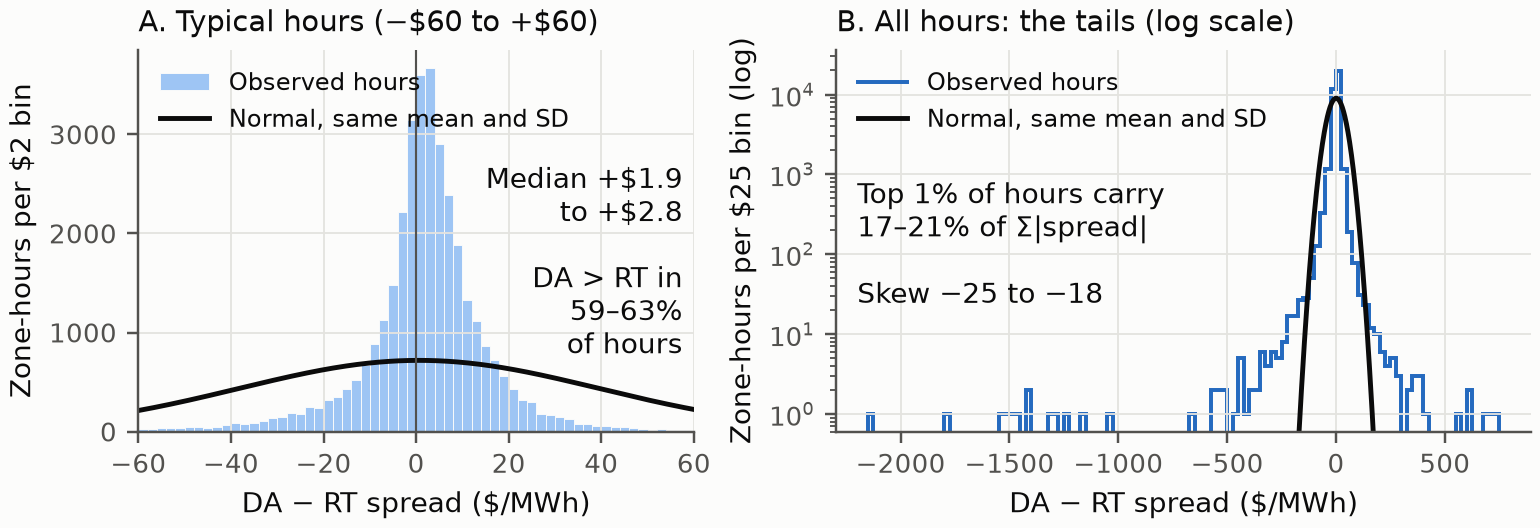

In [4]:
tv = eda.tail_vs_normal(panel)
display(tv)
plots.fig_spread_simple(panel, eda.spread_summary(panel), FIG / "fig1.png")
display(Image(FIG / "fig1.png", width=720))

## 3. Exploratory analysis

### Temperature and load (Figure 2)

Load is V-shaped in temperature in Houston, North and South, so a quadratic in temperature
explains far more of it than a straight line. West's load is largely industrial and much less
weather-sensitive.

,pearson,spearman,pearson_T_ge_65F,pearson_T_lt_65F,r2_T,r2_T_T2,r2_T_T2_hour_weekday,quadratic_min_load_at_F,corr_T_hour,load_mw_min,load_mw_max
zone,,,,,,,,,,,
houston,0.680,0.829,0.938,-0.698,0.462,0.890,0.936,57.370,0.198,"8,807.860","21,653.160"
north,0.351,0.509,0.923,-0.823,0.123,0.849,0.923,58.864,0.206,"10,984.870","32,432.330"
south,0.542,0.712,0.938,-0.767,0.294,0.861,0.911,60.612,0.265,"8,944.830","23,198.850"
west,0.404,0.466,0.538,-0.307,0.163,0.323,0.509,52.371,0.269,"7,127.930","11,881.610"


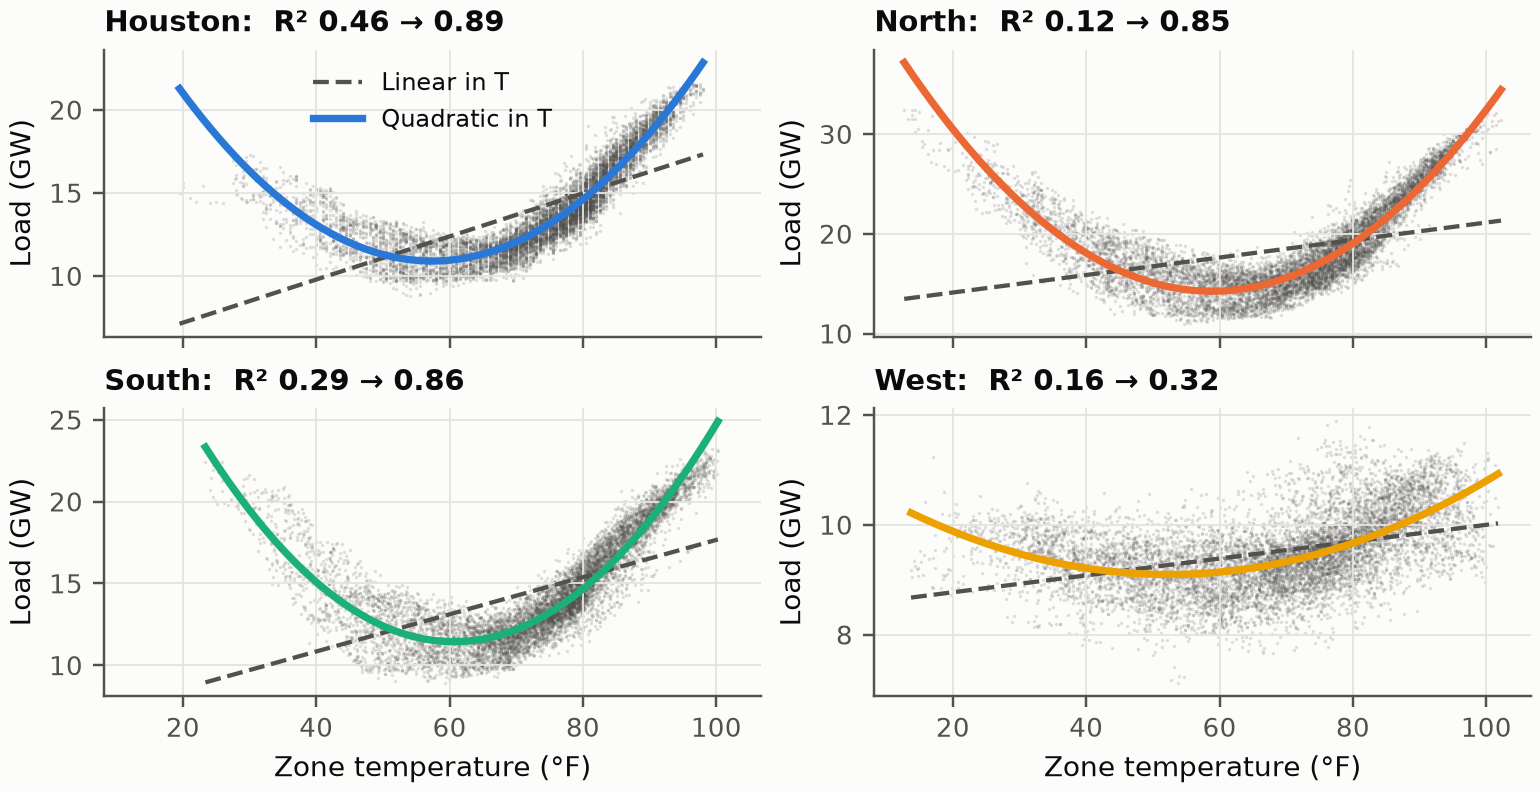

In [5]:
tl = eda.temp_load(panel)
display(tl)
plots.fig_temp_load_simple(panel, tl, FIG / "fig2.png")
display(Image(FIG / "fig2.png", width=900))

The same expanding-month validation used for the price models: how much lower is the
quadratic model's squared error in later months?

In [6]:
eda.temp_load_forward(panel)

,test_hours,sse_linear,sse_quadratic,mse_reduction_quadratic_vs_linear
zone,,,,
houston,6601,"36,090,757,123.250","5,847,542,093.406",0.838
north,6601,"153,099,703,510.209","20,925,475,067.882",0.863
south,6601,"59,622,147,898.224","8,727,979,508.686",0.854
west,6601,"3,244,846,906.743","2,430,485,360.000",0.251


### Collinearity and dependence

Because load depends strongly on temperature, the factor design is far from the orthogonal
design RSM assumes (D-11). Hourly series are also strongly autocorrelated, so 8,760 hours
carry much less information than 8,760 independent observations (D-26). The effective sample
size below is for estimating a mean (Bartlett weights, 168 lags).

In [7]:
display(analysis.correlation_check(panel, cfg["factors"]))
eda.effective_n_table(panel)

,corr_temp_f_load_mw,corr_temp_f_gas_price,corr_load_mw_gas_price,vif_temp_f,vif_load_mw,vif_gas_price
zone,,,,,,
houston,0.680,-0.617,-0.297,2.865,1.947,1.690
north,0.351,-0.623,-0.018,2.015,1.232,1.768
south,0.542,-0.602,-0.162,2.301,1.506,1.669
west,0.404,-0.589,-0.180,1.782,1.202,1.542


,n,neff_spread,neff_abs_spread,neff_rt_intrahour_std,neff_temp_f,neff_load_mw,neff_gas_price,distinct_gas_values,operating_days
zone,,,,,,,,,
houston,8760,3364,2016,4255,74,102,73,127,365
north,8760,3103,2016,4693,70,114,73,127,365
south,8760,1700,1121,4032,79,117,73,127,365
west,8760,1723,1473,3863,77,124,73,127,365


## 4. Extreme hours and system tightness

**Definitions (D-35).** An hour is *extreme* in a zone when its |spread| is in that zone's top
1%, so the base rate is 1% by construction and the comparisons are relative risks. *Tightness*
is ERCOT system net load (load minus wind and solar generation), ranked into deciles. The 90%
intervals come from a bootstrap that resamples whole days, because extremes cluster on a few
days.

In [8]:
rows, summ = eda.tail_by_net_load(panel)
cols = ["decile_kind", "sample", "zone", "rate_top_pct", "rate_rest_pct",
        "ratio_top_vs_rest", "ratio_ci05", "ratio_ci95", "share_of_events_in_top"]
summ[summ["zone"] == "all zones"][cols]

,decile_kind,sample,zone,rate_top_pct,rate_rest_pct,ratio_top_vs_rest,ratio_ci05,ratio_ci95,share_of_events_in_top
0,nl_decile,all days,all zones,5.993,0.450,13.310,8.173,21.200,0.597
5,nl_decile,excl. 2025-02-19/20,all zones,4.782,0.429,11.143,6.819,18.224,0.545
10,nl_decile_within_hour,all days,all zones,4.572,0.614,7.443,4.161,12.472,0.449
15,nl_decile_within_hour,excl. 2025-02-19/20,all zones,3.257,0.599,5.434,2.929,9.234,0.364


`nl_decile` ranks all hours; `nl_decile_within_hour` ranks within each hour of day, a
time-of-day robustness check that does not hold season, weather or renewables fixed. The same
comparison with fixed dollar thresholds:

In [9]:
fx = eda.tail_by_net_load_fixed(panel)
fx[fx["zone"] == "all zones"][["definition", "rate_top_pct", "rate_rest_pct",
                               "ratio_top_vs_rest", "ratio_ci05", "ratio_ci95", "event_days"]]

,definition,rate_top_pct,rate_rest_pct,ratio_top_vs_rest,ratio_ci05,ratio_ci95,event_days
0,|spread| > 50,13.442,1.782,7.543,5.822,9.702,150
5,RT above DA by > 50,6.878,1.316,5.227,3.395,7.488,104
10,|spread| > 100,5.251,0.393,13.355,8.076,21.492,51
15,RT above DA by > 100,2.511,0.352,7.135,3.346,12.531,35
20,|spread| > 250,1.570,0.063,24.750,8.959,59.386,15
25,RT above DA by > 250,0.913,0.063,14.400,2.301,39.026,12


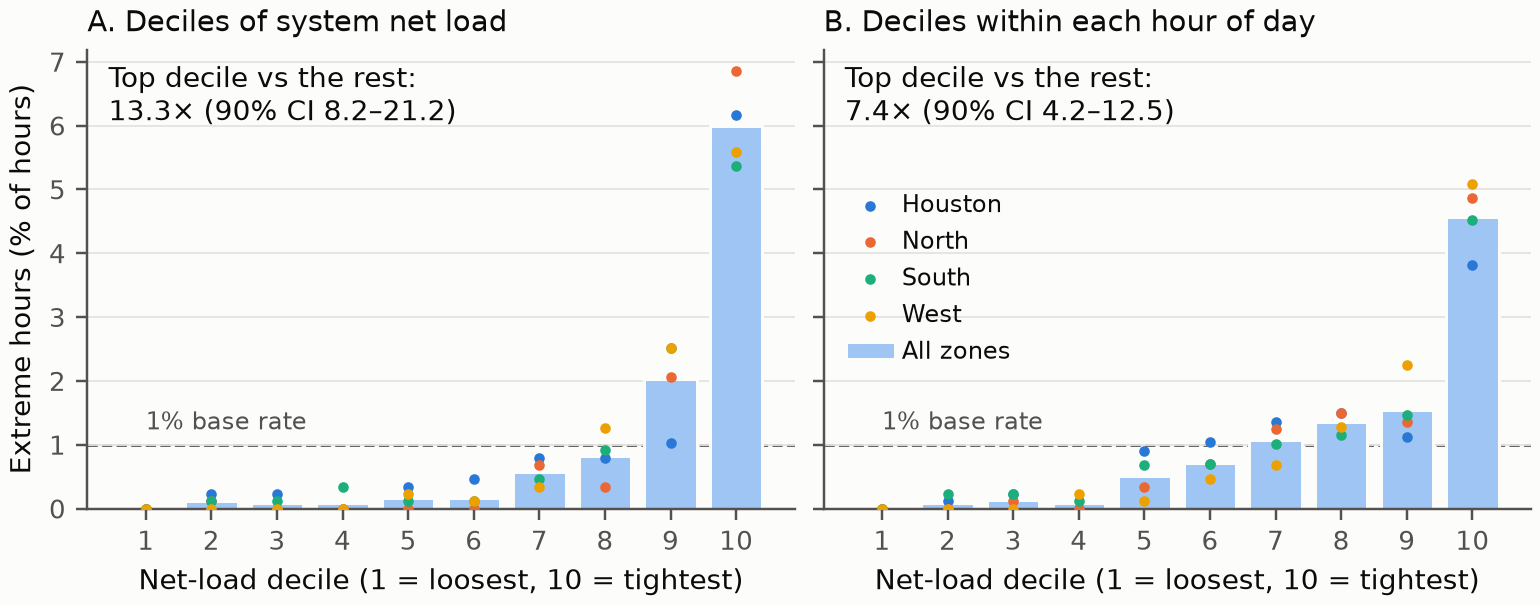

In [10]:
plots.fig_tail_by_net_load(rows, summ, FIG / "fig3.png")
display(Image(FIG / "fig3.png", width=900))

### The 16 May 2025 event (Figure 4)

The event day is chosen by a fixed rule, applied retrospectively: the day with the most
RT-above-DA extreme hours in the tightest decile, outside the February storm.

In [11]:
day = eda.representative_event_day(panel)
arch = study.raw_dir / "ercot" / "rt_prices_archive.parquet"
rt15 = ercot_archive.to_prices(pd.read_parquet(arch), gs.price_points(study),
                               study.section("prices").get("rt_point_type", "LZ"))
hourly, rt = eda.event_window(panel, rt15, day)
print("event day:", day)
h = hourly[hourly["zone"] == "houston"].set_index("hour_beginning")
h[["da_price", "rt_price", "spread", "extreme", "system_net_load_mw",
   "net_load_fc", "net_load_avail", "net_load_err_avail"]].loc[14:22]

event day: 2025-05-16


,da_price,rt_price,spread,extreme,system_net_load_mw,net_load_fc,net_load_avail,net_load_err_avail
hour_beginning,,,,,,,,
14,47.620,61.235,-13.615,False,"45,237.385","40,673.940","44,344.390","3,670.450"
15,60.630,86.107,-25.477,False,"47,739.473","42,693.580","46,563.670","3,870.090"
16,68.460,150.157,-81.698,True,"50,532.229","44,415.960","49,344.340","4,928.380"
17,75.480,163.835,-88.355,True,"52,671.029","45,813.030","50,836.970","5,023.940"
18,94.740,399.230,-304.490,True,"55,880.964","48,515.190","53,754.570","5,239.380"
19,183.870,"1,507.395","-1,323.525",True,"59,276.193","55,624.360","57,385.630","1,761.270"
20,163.580,376.695,-213.115,True,"59,058.567","57,230.869","58,814.840","1,583.971"
21,91.770,102.005,-10.235,False,"55,447.477","54,041.178","55,778.520","1,737.342"
22,72.590,57.980,14.610,False,"51,616.345","49,019.519","51,857.090","2,837.571"


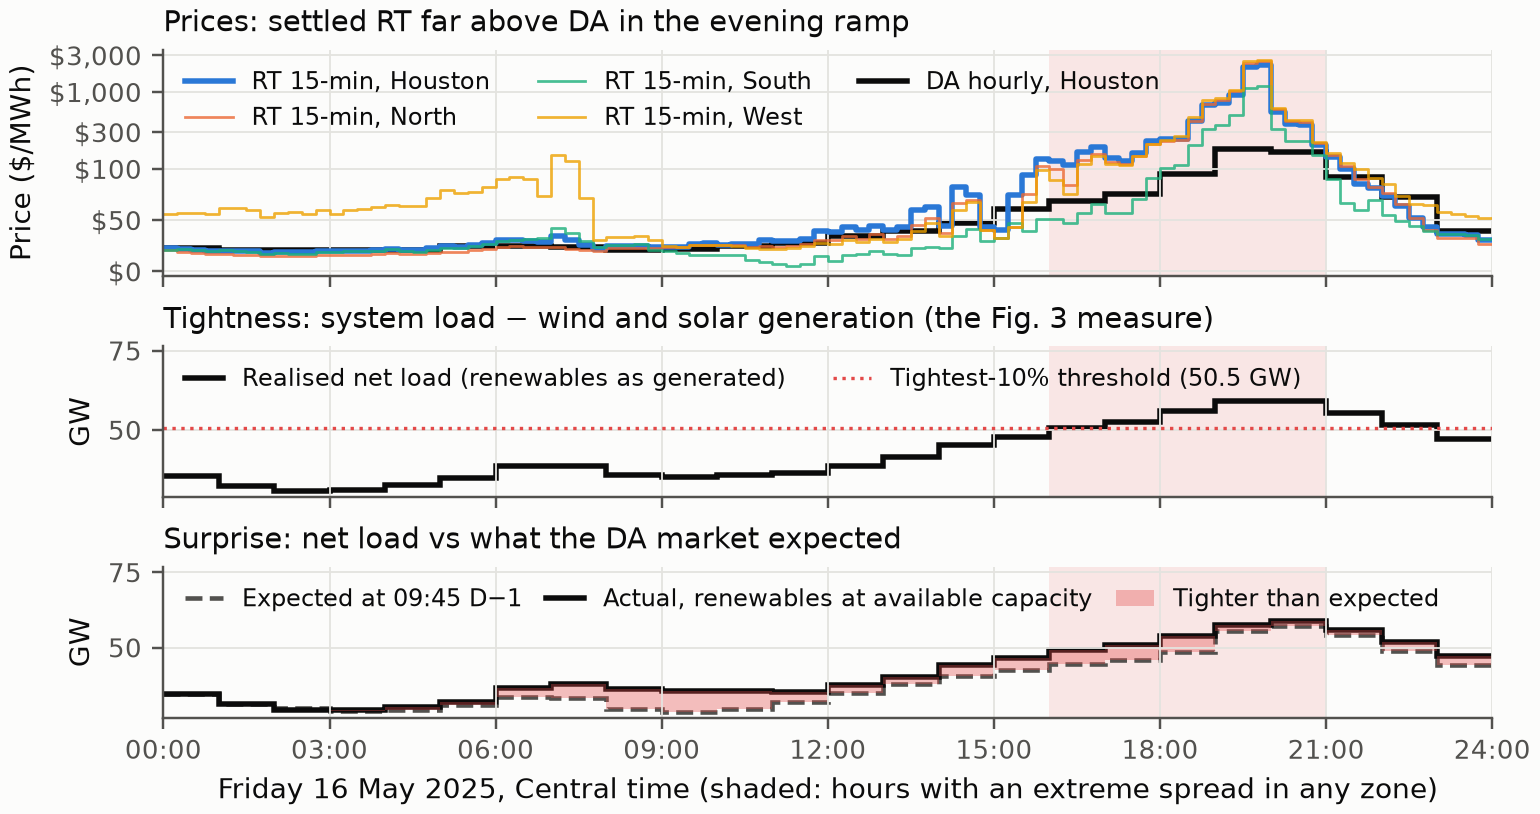

In [12]:
plots.fig_event_day(hourly, rt, FIG / "fig4.png")
display(Image(FIG / "fig4.png", width=900))

What the models predicted for Houston, fitted on January–April 2025 only: the surprise surface
S (a quadratic in the net-load surprise and expected net load) and the core quadratic M2 in
realised T, L and G.

In [13]:
ev = surprise.event_forward_predictions(panel, cfg, day)
ev.set_index("hour_beginning")[["spread", "net_load_err_avail", "pred_S_forward",
                                "pred_M2_forward"]].loc[16:21]

,spread,net_load_err_avail,pred_S_forward,pred_M2_forward
hour_beginning,,,,
16,-81.698,"4,928.380",-17.046,15.556
17,-88.355,"5,023.940",-17.612,14.989
18,-304.490,"5,239.380",-18.770,12.801
19,"-1,323.525","1,761.270",-1.898,9.814
20,-213.115,"1,583.971",-0.430,8.127
21,-10.235,"1,737.342",-2.406,7.058


## 5. Response surface regression: one zone in detail

Each zone is fitted separately. Factors are coded so that their 1st and 99th percentiles map to
±1 (D-13), the RTC+B go-live enters as an intercept shift (D-02, D-27), and inference uses
Newey–West standard errors with 48 lags (D-15, D-26). The NCSS-style output below is for
Houston's spread magnitude under the full quadratic M2; the classical ANOVA F-tests are printed
for comparison but are descriptive only, because the errors are serially dependent.

In [14]:
m2 = analysis.specs(cfg)["M2"]
d_h = analysis.prepare(panel, "houston", "abs_spread", cfg)
fit_h = analysis.fit_spec(d_h, "abs_spread", m2, cfg)
print(rsm.summary_text(fit_h, lof_bins=cfg["lof_bins"]))

RESPONSE SURFACE REGRESSION — abs_spread

Descriptive Statistics
            count     mean      min      max
temp_f      8,760  72.4642     19.5       98
load_mw     8,760 14,002.9 8,807.86 21,653.2
gas_price   8,760   3.5375     2.65     9.86
abs_spread  8,760  10.3958        0  1,500.4

Model Summary
  n = 8,760   order = 2   terms = 11   R^2 = 0.035101   adj R^2 = 0.033998
  coding  z = (x - center) / half_range
    temp_f         center         64   half_range       30.5
    load_mw        center  1.528e+04   half_range       5459
    gas_price      center      6.255   half_range      3.605

Sequential ANOVA (classical F; pure error from 8^k near-replicate cells, 149 occupied)
               df          ss       ms       F     p_value    incr_r2    F_pe        p_pe
source                                                                                   
blocks          1    8,136.47 8,136.47 9.50486  0.00205566 0.00104826 9.95934  0.00160588
regression      9     264,311 29,367.9 

In [15]:
rsm.design_diagnostics(fit_h)

,group,vif
term,,
regime_pre,block,1.110
temp_f,linear,26.777
load_mw,linear,44.334
gas_price,linear,9.965
temp_f^2,quadratic,6.396
temp_f*load_mw,lin x lin,10.670
temp_f*gas_price,lin x lin,25.377
load_mw^2,quadratic,4.263
load_mw*gas_price,lin x lin,37.036


## 6. Linear against quadratic models (Table 3)

The fair test of curvature keeps the inputs, hours and controls fixed and adds only the six
second-order terms: M1 against M2, and, with hour-of-day indicators, M1H against M3 (D-34).
In-sample R² can only rise when terms are added, so the comparison that matters is the error in
months the model has not seen (forward expanding-window validation over April–December, D-25).

In [16]:
cc = analysis.curvature_contribution(panel, study)

def later_month_error(row, lin, quad):
    # change in pooled squared error when the six terms are added (positive = quadratic worse)
    return (1 - row[f"fwd_skill_{quad}"]) / (1 - row[f"fwd_skill_{lin}"]) - 1

t3 = cc.set_index(["response", "zone"]).loc[:, ["r2_M1", "r2_M2", "r2_M1H", "r2_M3",
                                               "p_second_order", "p_second_order_with_hour",
                                               "pred_M1_mild_60_70F", "pred_M1_hot_1pct",
                                               "pred_M2_mild_60_70F", "pred_M2_hot_1pct"]]
t3["later_month_error_M2_vs_M1"] = cc.set_index(["response", "zone"]).apply(
    later_month_error, axis=1, lin="M1", quad="M2")
t3["later_month_error_M3_vs_M1H"] = cc.set_index(["response", "zone"]).apply(
    later_month_error, axis=1, lin="M1H", quad="M3")
t3.loc[["spread", "abs_spread", "imhr_da"]]

r2_M1  r2_M2  r2_M1H  r2_M3  p_second_order  p_second_order_with_hour  pred_M1_mild_60_70F  pred_M1_hot_1pct  pred_M2_mild_60_70F  \
response   zone                                                                                                                                         
spread     houston  0.002  0.005   0.004  0.008           0.358                     0.182                0.328             4.310                0.682   
           north    0.006  0.009   0.007  0.011           0.077                     0.092                0.758             4.369                1.185   
           south    0.017  0.031   0.020  0.033           0.228                     0.204                0.619             1.551                1.431   
           west     0.018  0.049   0.022  0.054           0.001                     0.001               -2.450             5.362                1.438   
abs_spread houston  0.027  0.035   0.057  0.070           0.020                     0.007                6.534            19.048                7.891   
           north    0.034  0.062   0.057  0.091           0.033                     0.003                6.087            21.670                8.563   
           south    0.048  0.088   0.060  0.111           0.004                     0.012                6.559            18.721                7.514   
           west     0.032  0.114   0.054  0.127           0.000                     0.000               18.937             9.131               10.793   
imhr_da    houston  0.182  0.184   0.375  0.381           0.289                     0.074                6.983            17.674                7.245   
           north    0.140  0.150   0.345  0.360           0.130                     0.009                7.252            17.516                7.467   
           south    0.197  0.208   0.360  0.374           0.001                     0.000                6.671            16.751                7.135   
           west     0.072  0.205   0.328  0.398           0.000                     0.000               13.615            13.135               11.174   

                    pred_M2_hot_1pct  later_month_error_M2_vs_M1  later_month_error_M3_vs_M1H  
response   zone                                                                                
spread     houston             6.067                       0.003                        0.004  
           north               9.912                       0.003                        0.003  
           south               5.600                       0.052                        0.062  
           west               -0.554                       0.037                        0.026  
abs_spread houston            20.615                       0.022                        0.018  
           north              26.031                       0.063                        0.031  
           south              22.668                       0.028                       -0.007  
           west               34.635                       0.005                        0.011  
imhr_da    houston            18.051                       0.038                        0.039  
           north              19.690                       0.052                        0.035  
           south              18.546                       0.115                        0.077  
           west               21.396                      -0.155                       -0.120

Reading the table:

* **Signed spread.** R² stays below 5%, the six terms are jointly significant only in West, and
  later-month error rises in every zone.
* **Spread magnitude.** The six terms are jointly significant in every zone and change the
  fitted shape (in West the linear model puts the hottest hours below mild ones, the quadratic
  above), but later-month error is still higher than the linear model's.
* **DA heat rate.** With identical hour-of-day controls, curvature raises later-month error in
  Houston, North and South and lowers it only in West.

Figure 5 shows the fitted magnitude surface over temperature and load at median gas, drawn only
where comparable hours exist (D-33). Hatching marks fitted magnitudes below zero.

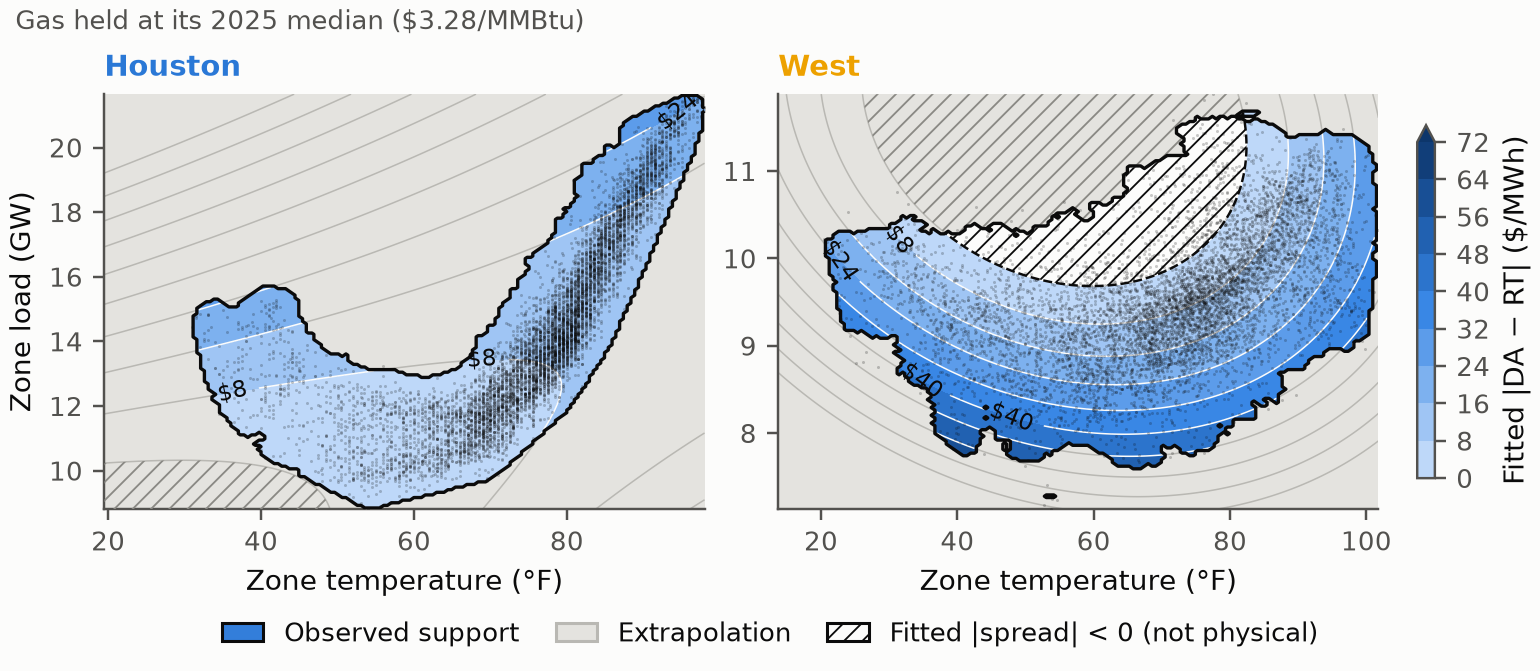

Share of fitted |spread| below zero (M2):


zone
houston   0.005
north     0.004
south     0.028
west      0.063
Name: share_fitted_negative_M2, dtype: float64

In [17]:
data = {z: analysis.prepare(panel, z, "abs_spread", cfg) for z in ["houston", "west"]}
fits = {z: analysis.fit_spec(data[z], "abs_spread", m2, cfg) for z in data}
plots.fig_surface_support(fits, data, FIG / "fig5.png")
display(Image(FIG / "fig5.png", width=900))
print("Share of fitted |spread| below zero (M2):")
cc[cc["response"] == "abs_spread"].set_index("zone")["share_fitted_negative_M2"]

## 7. Forecast surprises

The realised surface misses what matters for the spread's direction. Against the forecasts
published by 09:45 the day before (D-28), the net-load surprise (actual minus expected, with
renewables at available capacity) is far more strongly related to the spread than realised
temperature or load is.

In [18]:
rank_corr = (panel[panel["model_ok"]]
             .groupby("zone")
             .apply(lambda g: g[["net_load_err_avail", "temp_f", "load_mw"]]
                    .corrwith(g["spread"], method="spearman"))
             .rename(columns={"net_load_err_avail": "net-load surprise",
                              "temp_f": "temperature", "load_mw": "zonal load"}))
rank_corr

,net-load surprise,temperature,zonal load
zone,,,
houston,-0.467,0.045,0.070
north,-0.467,0.033,0.035
south,-0.442,0.049,0.003
west,-0.352,-0.005,0.090


## Summary

* Load is strongly curved in temperature, and the quadratic term carries forward to later
  months.
* Curvature is statistically clear in the size of the spread but not in its direction, and it
  does not lower the error in later months for either.
* Extreme spreads concentrate in the tightest hours, about 13 times as often as in other hours
  (7.4 times when ranking within hour of day). This is a descriptive association.
* On 16 May 2025 a surprise model matched the sign of the largest spike but not its size.

Further detail: `EDA_FINDINGS.md` (exploratory results), `MODEL_RESULTS.md` (the full model
ladder, the surprise models, the 2024 replication and the West basis decomposition) and
`DECISIONS.md` (every modelling choice).